# 01 · Fuzzy Scorer Comparison

**Goal:** pick the fuzzy scorers that match typed client and matter names to Matter Master, the firm's list of clients and matters.

Fuzzy matching scores how similar two strings are from 0 to 100, so "Bluefin Rbootlcs" still finds Bluefin Robotics. The top-scoring name is the match, and the gap to second place shows how sure it is.

Choices are made on TRAIN and checked once on VAL. TEST isn't used.

**Questions**
1. Which scorer matches typed client names best, especially names that look like another client's?
2. Does matching the client first help with matter names?
3. How low do clients that aren't in Matter Master score, and can a cutoff catch them?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from clean import normalize, is_ditto
from fuzzy import SCORERS, client_name_table, matter_name_table, score_table, match, compare_scorers, rank, exact_match_acc

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
RESULTS_DIR = Path("../results")
SHORTHAND_PATH = Path("../data/shorthand_bank.csv")   # billing shorthand, never read as client initials
TUNE, CHECK = "TRAIN", "VAL"

# Entries that resolve to one matter, so a typed client belongs to the true client
ONE_MATTER = ["CLEAN", "INCOMPLETE", "MESSY"]
CLIENT_FORMS = ["CANONICAL", "LISTED_ALIAS", "UNLISTED_ACRONYM", "CASE", "MISSPELLED", "SHORT", "TRUNCATED", "LOOKALIKE"]
MATTER_FORMS = ["CANONICAL", "CODENAME", "CODENAME_TYPO", "DESCRIPTOR"]

## 2. Load data

- A **client** is who the firm works for (Tidewater AI).
- A **matter** is one job for that client, like a deal or a lawsuit.
- The **CMID** holds both: in `4590.003`, `4590` is the client and `003` is the matter.

Everything is read as text so CMIDs keep their zeros.

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name="Time Entries", dtype=str)
matter_master = pd.read_excel(DATA_PATH, sheet_name="Matter Master", dtype=str)
assert set(raw["KEY: Split"]) == {"TRAIN", "VAL", "TEST"}

acronym_skip = pd.read_csv(SHORTHAND_PATH)["shorthand"].tolist()
client_names = client_name_table(matter_master, acronym_skip)
matter_names = matter_name_table(matter_master)
client_cmids = matter_master.groupby("Client")["CMID"].agg(set).to_dict()

print(f"{len(raw):,} entries | {client_names['id'].nunique()} clients ({len(client_names)} names) | "
      f"{matter_names['id'].nunique()} matters ({len(matter_names)} names)")
client_names.head()

4,000 entries | 35 clients (83 names) | 103 matters (120 names)


,name,id,kind,name_norm
0,Firm,Firm,canonical,firm
1,Harborlight Bio,Harborlight Bio,canonical,harborlight bio
2,Harborlight,Harborlight Bio,alias,harborlight
3,Harborline Biosciences,Harborline Biosciences,canonical,harborline biosciences
4,Harborline,Harborline Biosciences,alias,harborline


## 3. How the scorers behave

| Scorer | Idea |
|---|---|
| `ratio` | edit distance on the whole string |
| `partial_ratio` | best match of the shorter string inside the longer one |
| `token_sort_ratio` | sorts the words first, so word order doesn't matter |
| `token_set_ratio` | compares shared words, so extra words don't matter |
| `WRatio` | a weighted blend of the above |
| `JaroWinkler` | rewards matching starts, popular for short names |

The pairs below are real typed values from the data.

In [4]:
examples = [("bluefin rbootlcs", "bluefin robotics", "typo"),
            ("cobalt ridge ca", "cobalt ridge capital", "cut off"),
            ("pelican", "pelican row holdings", "short form"),
            ("northgate bank partners", "northgate capital partners", "look-alike typo (right)"),
            ("northgate bank partners", "northgate bank", "look-alike typo (wrong client)"),
            ("prh", "pelican row holdings", "acronym")]

pd.DataFrame([{"typed": a, "name": b, "case": c, **{s: round(f(a, b) * m) for s, (f, m) in SCORERS.items()}}
              for a, b, c in examples])

,typed,name,case,ratio,partial_ratio,token_sort_ratio,token_set_ratio,WRatio,JaroWinkler
0,bluefin rbootlcs,bluefin robotics,typo,88,88,88,88,88,96
1,cobalt ridge ca,cobalt ridge capital,cut off,86,100,86,89,86,95
2,pelican,pelican row holdings,short form,52,100,52,100,90,87
3,northgate bank partners,northgate capital partners,look-alike typo (right),82,74,82,88,83,91
4,northgate bank partners,northgate bank,look-alike typo (wrong client),76,100,76,100,90,92
5,prh,pelican row holdings,acronym,26,50,17,17,45,59


- **Partial scorers can't tell look-alikes apart.** `partial_ratio` and `token_set_ratio` give "pelican" a perfect score against any name containing it, so Pelican Row and Pelican Bay tie.
- **Sometimes only the gap decides.** "northgate bank partners" scores high against both Northgate clients with every scorer.
- **No scorer links initials to a name** ("prh" to Pelican Row Holdings). So initials are built from the client list and only count on an exact match (`client_acronyms` in `src/fuzzy.py`).

## 4. Client names

Only entries that resolve to one matter, where the typed client is some version of the true client's name.

In [5]:
def client_rows(split):
    keep = ((raw["KEY: Split"] == split) & raw["Client"].notna() & ~raw["Client"].map(is_ditto)
            & raw["KEY: Entry Category"].isin(ONE_MATTER) & raw["KEY: Client Surface"].isin(CLIENT_FORMS))
    df = raw.loc[keep, ["Client", "KEY: True Client", "KEY: Client Surface"]]
    df.columns = ["typed", "true_id", "form"]
    return df.assign(typed_norm=df["typed"].map(normalize)).reset_index(drop=True)


clients_train, clients_val = client_rows(TUNE), client_rows(CHECK)
client_results, client_ranked = compare_scorers(clients_train, client_names)
print(f"{len(clients_train)} TRAIN rows | exact match only: {exact_match_acc(clients_train, client_names):.1%}")
client_results.sort_values("top1_acc", ascending=False).round(3)

1322 TRAIN rows | exact match only: 79.0%


,top1_acc,recall@3,median_gap,min_gap
scorer,,,,
ratio,0.973,0.987,26.829000,0.575
token_sort_ratio,0.967,0.987,28.205000,0.575
WRatio,0.961,0.983,18.518999,0.000
JaroWinkler,0.958,0.989,10.909000,0.144
token_set_ratio,0.944,0.987,23.809999,0.000
partial_ratio,0.934,0.977,15.000000,0.000


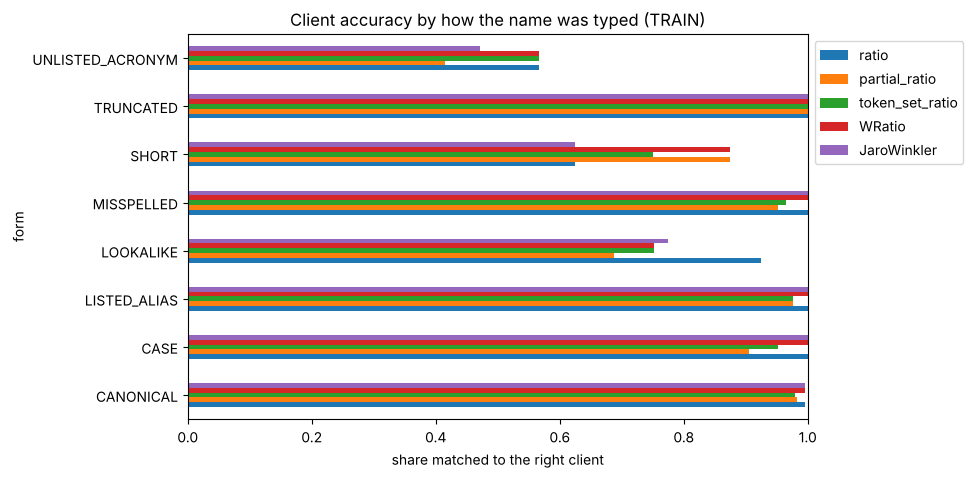

In [6]:
by_form = pd.DataFrame({s: r.groupby("form")["correct"].mean() for s, r in client_ranked.items()})
ax = by_form.drop(columns="token_sort_ratio").plot.barh(figsize=(8, 5), xlim=(0, 1), title="Client accuracy by how the name was typed (TRAIN)")
ax.set_xlabel("share matched to the right client")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

- **`ratio` is best at 97%** (99% leaving out unlisted initials), vs. 79% for exact matching alone.
- **Look-alike typos separate the scorers:** `ratio` gets 92% of them, while `partial_ratio`, `token_set_ratio`, and `WRatio` drop to 69 to 75%.
- **About half of unlisted initials match (57%).** Initials of three or more letters that belong to one client ("NCP") match exactly. Two-letter and shared ones ("SH", "HB", "CRC") can't be matched safely, so they're left for other clues.
- Short forms ("Pelican") go the other way, but there are only a handful, and many fit two clients anyway.

In [7]:
misses = client_ranked["ratio"].query("not correct")
misses[["typed", "form", "true_id", "pred_id", "gap"]].round(1)

,typed,form,true_id,pred_id,gap
19,HB,UNLISTED_ACRONYM,Harborline Biosciences,Harbor Light Partners,0.0
75,MT,UNLISTED_ACRONYM,Meridian Therapeutics,Mosaic Health Partners,6.7
132,Halvorsen Industries,LOOKALIKE,Halvorsen Industrial,Halverson Industries,0.0
142,SH,UNLISTED_ACRONYM,Solace Health,Harbor Light Partners,0.0
146,Cobalt Ridge,CANONICAL,Cobalt Ridge Partners,Cobalt Ridge Capital,2.3
166,Meridian Therapeutics Systems,LOOKALIKE,Meridian Thermal Systems,Meridian Therapeutics,1.0
205,HB,UNLISTED_ACRONYM,Harborlight Bio,Harbor Light Partners,0.0
207,CN,UNLISTED_ACRONYM,Copperline Networks,Juniper Peak Capital,0.0
229,CN,UNLISTED_ACRONYM,Copperline Networks,Juniper Peak Capital,0.0
311,Pelican,SHORT,Pelican Row Holdings,Pelican Bay Holdings,0.0


- **Most misses are two-letter or shared initials.** The rest are short names that fit two clients ("Pelican", "Northgate") or typos between look-alike clients. The narrative or timekeeper history has to settle these.

## 5. Matter names

Rows where a matter name or codename was typed, matched two ways:
- **All matters:** against every matter in Matter Master
- **Within the client:** match the typed client first, then only that client's matters

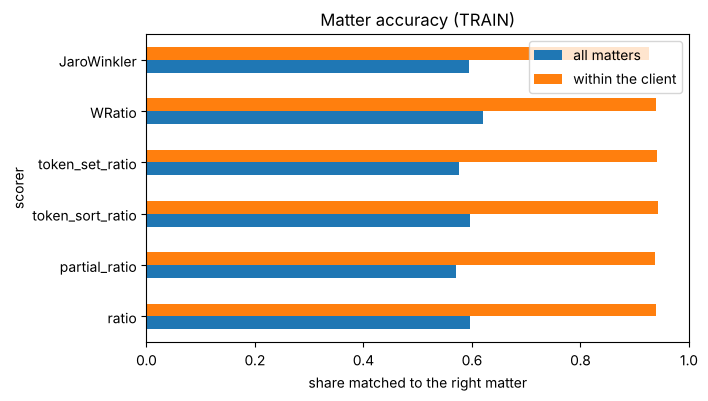

,top1_acc,recall@3,median_gap,min_gap
scorer,,,,
ratio,0.939,0.953,54.839001,0.0
partial_ratio,0.937,0.955,44.827999,0.0
token_sort_ratio,0.943,0.961,57.143002,0.0
token_set_ratio,0.942,0.961,53.487999,0.0
WRatio,0.939,0.955,53.784000,0.0
JaroWinkler,0.926,0.955,37.328999,0.0


In [8]:
def matter_rows(split):
    keep = ((raw["KEY: Split"] == split) & raw["Matter"].notna() & raw["KEY: Entry Category"].isin(ONE_MATTER)
            & raw["KEY: Matter Surface"].isin(MATTER_FORMS))
    df = raw.loc[keep, ["Matter", "Client", "KEY: True CMID", "KEY: Matter Surface"]]
    df.columns = ["typed", "typed_client", "true_id", "form"]
    return df.assign(typed_norm=df["typed"].map(normalize)).reset_index(drop=True)


def client_scope(df):
    top = [match(c, client_names, k=1) for c in df["typed_client"]]
    return [client_cmids[t[0][0]] if t else set() for t in top]


matters_train, matters_val = matter_rows(TUNE), matter_rows(CHECK)
all_matters, _ = compare_scorers(matters_train, matter_names)
within_client, matter_ranked = compare_scorers(matters_train, matter_names, allowed=client_scope(matters_train))

ax = pd.DataFrame({"all matters": all_matters["top1_acc"], "within the client": within_client["top1_acc"]}).plot.barh(
    figsize=(7, 4), xlim=(0, 1), title="Matter accuracy (TRAIN)")
ax.set_xlabel("share matched to the right matter")
plt.show()
within_client.round(3)

- **All matters: about 60%.** "General Corporate", the catch-all for a client's routine work, belongs to 18 clients, so the name alone can't pick one.
- **Within the client: 92 to 94% for every scorer.** Finding the client first is what makes matter names work.
- The scorers are within 2 points of each other, so the order of steps matters more than the scorer.

In [9]:
matter_ranked["token_sort_ratio"].query("not correct")[["typed", "typed_client", "form", "true_id", "pred_id"]].head(8)

,typed,typed_client,form,true_id,pred_id
21,General Fund Matters,NaN,CODENAME,5524.002,2215.001
35,annual meeting,MT,DESCRIPTOR,6103.004,8820.002
37,sec reporting,Meridian Therapeutics,DESCRIPTOR,6103.004,6103.001
48,sec,Meridian Therapeutics,DESCRIPTOR,6103.004,6103.001
54,Fund II Formation,NaN,CODENAME,9140.001,2215.002
89,gen,Cobalt Ridge Capital,DESCRIPTOR,5520.004,5520.002
90,gen corp,HB,DESCRIPTOR,2201.001,7215.005
92,Fund II Formation,NaN,CODENAME,9140.001,2215.002


- What's left are short descriptors ("sec", "gen", "annual meeting") and matters typed with no client or only initials.

## 6. Clients that aren't in Matter Master

Some entries are for a new client the firm hasn't opened yet, and the right call is `NO_MATCH`. The question is how far these names score from real clients. Each typed name keeps its best score against any known client.

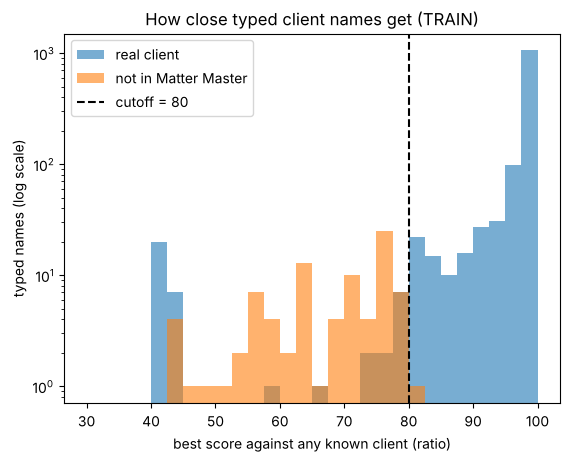

In [10]:
new_clients = raw[(raw["KEY: Split"] == TUNE) & (raw["KEY: Client Surface"] == "NOT_IN_MATTER_MASTER") & raw["Client"].notna()]
real_best = score_table(clients_train["typed_norm"], client_names, "ratio").max(axis=1)
new_best = score_table(new_clients["Client"].map(normalize), client_names, "ratio").max(axis=1)

bins = np.arange(30, 102.5, 2.5)
plt.hist(real_best, bins=bins, alpha=0.6, label="real client")
plt.hist(new_best, bins=bins, alpha=0.6, label="not in Matter Master")
plt.axvline(80, color="black", linestyle="--", label="cutoff = 80")
plt.yscale("log")
plt.xlabel("best score against any known client (ratio)")
plt.ylabel("typed names (log scale)")
plt.title("How close typed client names get (TRAIN)")
plt.legend()
plt.show()

In [11]:
cutoffs = pd.DataFrame({"real clients kept": [(real_best >= c).mean() for c in range(50, 96, 5)],
                        "new clients caught": [(new_best < c).mean() for c in range(50, 96, 5)]},
                       index=range(50, 96, 5)).rename_axis("cutoff")
cutoffs["average"] = cutoffs.mean(axis=1)
NO_MATCH_CUTOFF = int(cutoffs["average"].idxmax())
print("Suggested NO_MATCH cutoff:", NO_MATCH_CUTOFF)
cutoffs.round(3)

Suggested NO_MATCH cutoff: 80


,real clients kept,new clients caught,average
cutoff,,,
50,0.980,0.100,0.540
55,0.980,0.133,0.556
60,0.979,0.256,0.617
65,0.979,0.422,0.701
70,0.978,0.478,0.728
75,0.977,0.633,0.805
80,0.970,0.989,0.979
85,0.942,1.000,0.971
90,0.922,1.000,0.961


- **Real clients almost always score 80 or more,** and the exceptions are mostly two-letter initials. New clients stay at 80 or below.
- **A cutoff of 80 keeps 97.0% of real clients and catches 98.9% of new ones.** Notebook 03 starts from it and tunes it on TRAIN.
- **The cutoff isn't the whole answer:** the closest new clients look like real ones ("Pelican P", "Northgate Credit").

## 7. Choose scorers and check on VAL

- **Client scorer:** best top-1 accuracy on TRAIN, then the safest close call (biggest smallest gap)
- **Matter scorer:** best top-1 accuracy within the client on TRAIN, then recall@3

In [12]:
CLIENT_SCORER, CLIENT_RUNNER_UP = client_results.sort_values(["top1_acc", "min_gap"], ascending=False).index[:2]
MATTER_SCORER, MATTER_RUNNER_UP = within_client.sort_values(["top1_acc", "recall@3"], ascending=False).index[:2]
print(f"client: {CLIENT_SCORER} (runner-up {CLIENT_RUNNER_UP}) | matter: {MATTER_SCORER} (runner-up {MATTER_RUNNER_UP})")

val = pd.DataFrame({
    "client": [rank(clients_val, client_names, CLIENT_SCORER)["correct"].mean(), client_results.loc[CLIENT_SCORER, "top1_acc"]],
    "matter (within client)": [rank(matters_val, matter_names, MATTER_SCORER, client_scope(matters_val))["correct"].mean(),
                               within_client.loc[MATTER_SCORER, "top1_acc"]],
}, index=["VAL", "TRAIN"]).T
val.round(3)

client: ratio (runner-up token_sort_ratio) | matter: token_sort_ratio (runner-up token_set_ratio)


,VAL,TRAIN
client,0.970,0.973
matter (within client),0.909,0.943


- **The client scorer holds on VAL** (97%).
- **Matter accuracy drops a few points on VAL** (91% vs. 94%), which has slightly more short descriptors. It wasn't tuned further.

## 8. Save

In [13]:
RESULTS_DIR.mkdir(exist_ok=True)
choice = {"client_scorer": CLIENT_SCORER, "client_runner_up": CLIENT_RUNNER_UP,
          "matter_scorer": MATTER_SCORER, "matter_runner_up": MATTER_RUNNER_UP, "no_match_cutoff": NO_MATCH_CUTOFF}
(RESULTS_DIR / "01_scorer_choice.json").write_text(json.dumps(choice, indent=2))
choice

{'client_scorer': 'ratio',
 'client_runner_up': 'token_sort_ratio',
 'matter_scorer': 'token_sort_ratio',
 'matter_runner_up': 'token_set_ratio',
 'no_match_cutoff': 80}

## 9. Findings

### Choices
- **Client scorer: `ratio`.** 97% on TRAIN and VAL, vs. 79% for exact matching alone.
- **Matter scorer: `token_sort_ratio`, within the client.** 94% on TRAIN and 91% on VAL, vs. about 60% against all matters.
- **`NO_MATCH` cutoff: start at 80.** New clients score 80 or below against every real client.
- **Initials:** built from the client list and matched exactly, they cover about half of unlisted initials.

### Tradeoffs
- **Strict vs. forgiving scorers:** scorers that reward partial overlap are more forgiving of short forms, but they score a typo high against both look-alike clients. `ratio` is stricter, which is safer when two clients look alike.
- **Exact initials only:** matching initials loosely would catch more of them, but two-letter and shared initials would point to the wrong client. Leaving them for other clues trades some coverage for fewer wrong matches.

### Left for later steps
- Two-letter and shared initials ("SH", "HB"), short forms shared by two clients ("Pelican"), and vague matter descriptors ("sec").

### Limitations
- The typed names are synthetic, built from a fixed set of typo and short-form patterns, so real typing errors may be messier.
- Only character-based scorers are compared. Nicknames need the firm's alias list or other clues.

### Next steps
- `02_feature_building`: use these scorers for the name clues, alongside the CMID, narrative, dates, and timekeeper history.
- `03_baseline_rules`: start the `NO_MATCH` cutoff at 80 and tune it on TRAIN.